## Team overview

| Team member | Question they will answer | Changed since the proposal? (Yes / No) |
|---|---|---|
| Sean Qin | Which stations repeatedly have morning net departures (6–10 a.m.), and how often do later net arrivals (10 a.m.–8 p.m.) offset them? | No |
| Daniel Cai | At morning-deficit stations, do members and casual riders reinforce or offset each other's imbalances? | No |
| Surya Venkataraman | How much later inbound traffic comes from stations that received a station's morning departures? | No |
| Anjeli Noémi (Mimi) | Within stations, how does recovery differ between rainy and dry days, across temperatures, and between weekdays and weekends? | No |

**Presentation session:** *TODO (team): keep one: Session 1 (Wed, Nov 25) / Session 2 (Fri, Dec 11)*

**If any question changed since the proposal, explain why in one or two sentences:** No questions have changed.

In [2]:
# Libraries used in this notebook. Add any others your team needs.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1) Data loaded and cleaned
*By Sean Qin (shared cleaning notebook `notebooks/01_data_cleaning.ipynb`; all four members review it)*

**Data:** September 2026 Divvy trips (770,562 rides) plus Meteostat daily weather for Chicago Midway.
The full cleaning runs in `notebooks/01_data_cleaning.ipynb`. Here we load its outputs, which are saved in the repo, and show that they are ready to analyze.

In [3]:
# Load the data. Use a relative path so the notebook runs on any teammate's computer.
DATA_PATH = "../data/processed/"
station_day = pd.read_csv(DATA_PATH + "station_day.csv")       # one row per station x day (weather already joined)
exclusions = pd.read_csv(DATA_PATH + "exclusions.csv")         # rides removed by each cleaning rule
weather = pd.read_csv(DATA_PATH + "weather_daily.csv")         # one row per day

# Size and first rows
print(station_day.shape)
station_day.head()

(30383, 20)


,station_id,day,later_arrivals,later_departures,morning_arrivals,morning_departures,morning_net_departures,later_net_arrivals,has_morning_deficit,recovery,full_recovery,station_name,date,weekday,day_type,temp_mean_c,temp_min_c,temp_max_c,prcp_mm,rainy
0,CHI00005,1,20,14,1,5,4,6,True,1.500000,True,Milwaukee Ave & Wabansia Ave,2026-09-01,Tuesday,Weekday,29.5,25.0,34.4,0.0,0.0
1,CHI00005,2,22,21,2,4,2,1,True,0.500000,False,Milwaukee Ave & Wabansia Ave,2026-09-02,Wednesday,Weekday,30.2,25.6,35.6,0.0,0.0
2,CHI00005,3,12,13,0,7,7,-1,True,-0.142857,False,Milwaukee Ave & Wabansia Ave,2026-09-03,Thursday,Weekday,29.0,26.1,33.3,0.0,0.0
3,CHI00005,4,30,32,2,2,0,-2,False,NaN,False,Milwaukee Ave & Wabansia Ave,2026-09-04,Friday,Weekday,29.4,25.6,33.9,0.0,0.0
4,CHI00005,5,30,35,7,2,-5,-5,False,NaN,False,Milwaukee Ave & Wabansia Ave,2026-09-05,Saturday,Weekend,25.7,22.8,28.3,0.0,0.0


In [4]:
# Column types and missing values
station_day.info()
station_day.isna().sum().sort_values(ascending=False).head()

<class 'pandas.DataFrame'>
RangeIndex: 30383 entries, 0 to 30382
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   station_id              30383 non-null  str    
 1   day                     30383 non-null  int64  
 2   later_arrivals          30383 non-null  int64  
 3   later_departures        30383 non-null  int64  
 4   morning_arrivals        30383 non-null  int64  
 5   morning_departures      30383 non-null  int64  
 6   morning_net_departures  30383 non-null  int64  
 7   later_net_arrivals      30383 non-null  int64  
 8   has_morning_deficit     30383 non-null  bool   
 9   recovery                11408 non-null  float64
 10  full_recovery           30383 non-null  bool   
 11  station_name            30383 non-null  str    
 12  date                    30383 non-null  str    
 13  weekday                 30383 non-null  str    
 14  day_type                30383 non-null  str    
 

recovery        18975
station_id          0
station_name        0
prcp_mm             0
temp_max_c          0
dtype: int64

In [5]:
# Cleaning steps done so far (full code and checks are in notebooks/01_data_cleaning.ipynb).
# 1) Removed duplicate and invalid rides:
exclusions

,step,removed,remaining
0,Raw rides,0,770562
1,Near-duplicate (second copy),4,770558
2,Duration < 60 s,18610,751948
3,Duration > 24 h,633,751315


In [6]:
# 2) Combined two datasets: trips -> station-day flows, then joined daily weather on the day of the month.
#    The merge is many-to-one, so we predict the row count stays the same, and every day should match.
check = station_day.drop(columns=["temp_mean_c", "temp_min_c", "temp_max_c", "prcp_mm", "rainy"]).merge(
    weather, on="day", how="left", validate="many_to_one", indicator=True)
print("rows before:", len(station_day), "| rows after:", len(check))
check["_merge"].value_counts()

rows before: 30383 | rows after: 30383


_merge
both          30383
left_only         0
right_only        0
Name: count, dtype: int64

**Cleaning summary.**

- **What we have cleaned so far:**
  - Parsed timestamps and checked for duplicates: no repeated ride IDs, and 4 near-duplicate rides were dropped.
  - Removed rides shorter than 60 s (18,610, mostly false starts or re-docks) and longer than 24 h (633, mostly lost bikes).
  - Confirmed that station IDs and names match one-to-one.
  - Built departure and arrival events from each ride (`concat`).
  - Reshaped the events into station-day flows (`pivot_table`) and computed recovery = later net arrivals ÷ morning net departures.
  - Joined day type (Labor Day kept separate) and daily weather (`merge` with `validate=` and `indicator=True`; every row matched).
- **Missing values:** 21–22% of rides have no start or end station, and all of them are e-bikes parked away from a dock. We keep these rides and count only endpoints with a known station, so e-bike flows are undercounted. Missing precipitation would stay NaN, never 0, but September has none missing.
- **What cleaning is still left:** Surya's route table (rides with both stations known, 66.6% of kept rides). Sensitivity versions of the duration cutoffs.
- **Rows and columns before → after cleaning:**
  - Trips: 770,562 × 13 → 751,315 × 23 (97.5% kept).
  - Station-day table: 30,383 rows × 20 columns, of which 11,408 station-days start with a morning deficit.

## 2) Early results

### Question 1: Which stations keep losing bikes in the morning, and do they get them back?
*By Sean Qin*

In [7]:
# Weekday morning-deficit station-days (weekend riding behaves differently; Labor Day is separate)
deficit = station_day[station_day["has_morning_deficit"]]
by_day_type = deficit.groupby("day_type").agg(
    station_days=("recovery", "count"),
    full_recovery_rate=("full_recovery", "mean"),
    later_net=("later_net_arrivals", "sum"),
    morning_net=("morning_net_departures", "sum"),
)
by_day_type["pooled_recovery"] = by_day_type["later_net"] / by_day_type["morning_net"]
by_day_type[["station_days", "full_recovery_rate", "pooled_recovery"]].round(3)

,station_days,full_recovery_rate,pooled_recovery
day_type,,,
Labor Day,290,0.390,0.230
Weekday,8548,0.386,0.567
Weekend,2570,0.342,0.102


264 recurring-deficit stations out of 1,523 active on weekdays


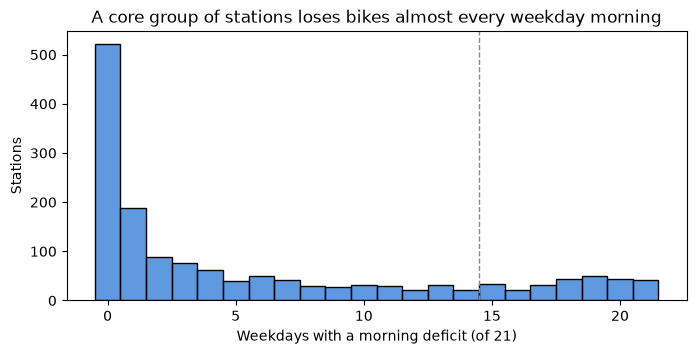

In [8]:
# Recurring-deficit stations: a morning deficit on at least 15 of the 21 non-holiday weekdays
weekday = station_day[station_day["day_type"] == "Weekday"]
per_station = weekday.groupby("station_name").agg(
    weekday_deficit_days=("has_morning_deficit", "sum"),
    mean_morning_net_dep=("morning_net_departures", "mean"),
)
recurring = per_station[per_station["weekday_deficit_days"] >= 15]
print(f"{len(recurring)} recurring-deficit stations out of {len(per_station):,} active on weekdays")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=per_station, x="weekday_deficit_days", discrete=True, color="#2a78d6", ax=ax)
ax.axvline(14.5, color="#8a8984", ls="--", lw=1)
ax.set(xlabel="Weekdays with a morning deficit (of 21)", ylabel="Stations",
       title="A core group of stations loses bikes almost every weekday morning")
plt.show()

![Cumulative net flow since 6 a.m. at recurring-deficit stations, by how often they recover (from notebooks/02_station_recovery_sean.ipynb)](../figures/sean_cumulative_hourly_flow.png)

**What this shows so far:**

- **Recurring stations:** 264 stations start the day short on at least 15 of 21 weekdays.
- **Partial recovery:** at those stations, later traffic replaces about 62% of the morning loss overall, but the station fully recovers by 8 p.m. on only 39% of days.
- **Timing:** recovery comes mostly from the 3–6 p.m. commute, and the stations that rarely recover are still short at midnight.
- **Weekends:** only about 10% of weekend morning losses come back, compared with about 57% on weekdays.

### Question 2: Do members and casual riders reinforce or offset each other's imbalances?
*By Daniel Cai*

In [ ]:
# Keep weekday station-days that start the day short (same sample as Question 1)
by_rider = pd.read_csv(DATA_PATH + "station_day_by_rider.csv")   # one row per station x day x rider group
keys = station_day.loc[(station_day["day_type"] == "Weekday") & station_day["has_morning_deficit"],
                       ["station_id", "day"]]
dr = by_rider.merge(keys, on=["station_id", "day"], how="inner", validate="many_to_one")

# Bikes lost in the morning vs brought back later, by rider group
by_group = dr.groupby("member_casual")[["morning_net_departures", "later_net_arrivals"]].sum()
by_group["share_of_morning_deficit"] = by_group["morning_net_departures"] / by_group["morning_net_departures"].sum()

# How often casual riders push the same way (also take bikes out) vs the opposite way
casual = dr[dr["member_casual"] == "casual"]
print(f"Casual riders also net-depart on {(casual['morning_net_departures'] > 0).sum() / len(keys):.0%} "
      f"of deficit station-days and net-arrive on {(casual['morning_net_departures'] < 0).sum() / len(keys):.0%}")
display(by_group.round(2))

ax = by_group[["morning_net_departures", "later_net_arrivals"]].T.plot.bar(
    color={"member": "#2a78d6", "casual": "#eb6834"}, figsize=(7, 3.5), rot=0)
ax.axhline(0, color="#8a8984", lw=1)
ax.set(xticklabels=["Morning net departures\n(6–10 a.m.)", "Later net arrivals\n(10 a.m.–8 p.m.)"],
       ylabel="Bikes (weekday deficit station-days)", title="Both groups drain bikes; only members bring them back")
plt.show()

**What this shows so far:**

- Casual riders add to the morning loss instead of canceling it out. They cause about 20% of it.
- Members bring the bikes back later in the day. Casual riders don't.
- Next: check weekends and bike type.

### Question 3: How much later inbound traffic comes back along the morning routes?
*By Surya Venkataraman*

In [10]:
# TODO (Surya): early analysis or plot for question 3
# Suggested input: ../data/processed/trips_clean.csv (run notebook 01 to create it)

**What this shows so far:** *TODO (Surya)*

### Question 4: How does recovery differ by rain, temperature, and weekday vs weekend?
*By Anjeli Noémi (Mimi)*

rainy      0.0  1.0
day_type           
Labor Day    1    0
Weekday     16    5
Weekend      6    2
                 station_days  full_recovery_rate  median_recovery
day_type  rain                                                    
Labor Day Dry             290               0.390              0.0
Weekday   Dry            6775               0.380              0.5
          Rainy          1773               0.412              0.5
Weekend   Dry            2099               0.333              0.0
          Rainy           471               0.382              0.0


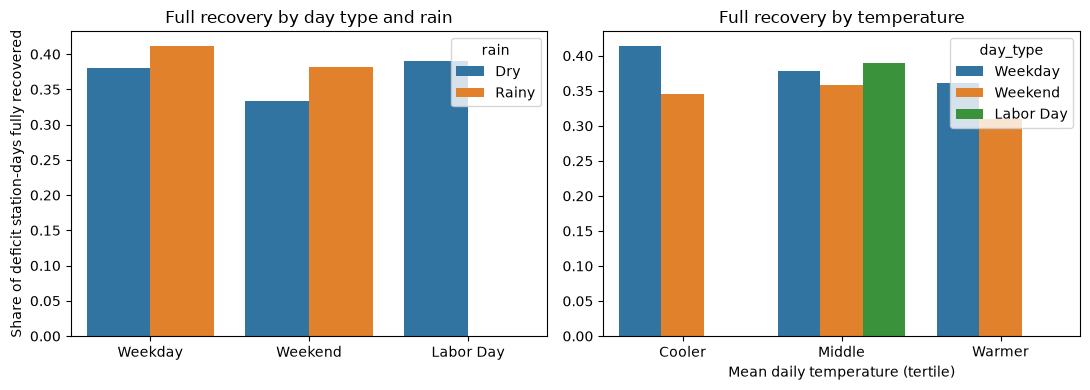

In [11]:
# TODO (Mimi): early analysis or plot for question 4
# Suggested input: ../data/processed/station_day.csv (weather already joined)


sd = pd.read_csv('../data/processed/station_day.csv')

# Only station-days that started the day short (recovery is defined for these)
deficit = sd[sd['has_morning_deficit']].copy()
deficit['rain'] = deficit['rainy'].map({0.0: 'Dry', 1.0: 'Rainy'})
deficit['temp_group'] = pd.qcut(deficit['temp_mean_c'], 3, labels=['Cooler', 'Middle', 'Warmer'])

# How many distinct days fall in each weather / day-type group?
days = sd.drop_duplicates('date')
print(pd.crosstab(days['day_type'], days['rainy']))

# Full-recovery rate by day type and rain
summary = (deficit.groupby(['day_type', 'rain'])
           .agg(station_days=('station_id', 'size'),
                full_recovery_rate=('full_recovery', 'mean'),
                median_recovery=('recovery', 'median'))
           .round(3))
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=deficit, x='day_type', y='full_recovery', hue='rain', errorbar=None, ax=axes[0])
axes[0].set(title='Full recovery by day type and rain', xlabel='', ylabel='Share of deficit station-days fully recovered')
sns.barplot(data=deficit, x='temp_group', y='full_recovery', hue='day_type', errorbar=None, ax=axes[1])
axes[1].set(title='Full recovery by temperature', xlabel='Mean daily temperature (tertile)', ylabel='')
plt.tight_layout()
plt.savefig('../figures/mimi_recovery_weather_daytype.png', dpi=150, bbox_inches='tight')
plt.show()

**What this shows so far:**

- **Weekday vs weekend:** 38.7% of deficit station-days fully recover on weekdays, compared with 34.2% on weekends. The median recovery is 0.5 on weekdays (half the morning deficit comes back) but 0.0 on weekends.
- **Rain:** Surprisingly, rainy days show slightly *higher* full recovery than dry days, both on weekdays (41.2% vs 38.0%) and weekends (38.2% vs 33.3%), based on 7 rainy days. One possible reason is that rain reduces riding overall, so deficits are smaller and easier to make up. Daily precipitation also doesn't tell us *when* it rained.
- **Temperature:** Cooler weekdays have the highest full-recovery rate (about 41%); weekends are lower than weekdays at every temperature level.
- **Caveat:** Weather only varies by day, and September has 21 weekdays, 8 weekend days, and 1 Labor Day, with only 7 rainy days. The differences are only 3–5 percentage points, so these are early patterns, not conclusions.

## 3) What remains
*Proposed. The team should confirm owners and dates before the check-in.*

| Task | Owner | Target date |
|---|---|---|
| Early result for rider contributions (member vs casual flows at deficit stations) | Daniel | Sun, Nov 22 |
| Early result for route contributions (same-day reverse-route arrivals) | Surya | Sun, Nov 22 |
| Early result for weather and day type (rainy vs dry, weekday vs weekend) | Mimi | Sun, Nov 22 |
| Review shared cleaning choices (duration cutoffs, missing e-bike stations) | All | Sun, Nov 22 |
| Finish each member's main figure, supporting table, and sensitivity check | Each member | *TODO: depends on session* |
| Slides (due the day before the session) and rehearsal | All | *TODO: depends on session* |
| Final report and code notebook | All | Fri, Dec 11, 11:59 pm |

**Biggest risk to finishing on time:** three of the four questions don't have early results yet, and Surya still needs repo access and needs to generate `trips_clean.csv` locally.

## 4) Questions for the mentor

1. **Unstable ratio for small deficits.** Recovery (later net arrivals ÷ morning net departures) jumps when the morning deficit is only 1–2 bikes; one station-day has a ratio of 55. We report the median, the full-recovery rate, and a pooled ratio side by side. Is that a reasonable approach, or should our main results use only deficits of at least 5 bikes (2,562 of 11,408 station-days)?
2. **E-bikes with no station.** 27.6% of e-bike rides have no start station, so we count only endpoints at known stations. Their coordinates are rounded to two decimals (about 1 km), which is too coarse to match to a station. Is it enough to report this as a limitation and show the classic-bike results separately?
3. **Few rainy days.** Only 5 weekdays had any rain and only 2 had heavy rain (≥ 2.5 mm). Is a descriptive comparison with day counts shown acceptable, or should Mimi focus more on temperature and day type?
4. **Weekday-only analyses.** Weekday and weekend recovery differ a lot (57% vs 10% pooled). Should the station, rider, and route analyses use weekdays only and leave the weekend comparison to Mimi's question?

## Mentor feedback *(fill in during or right after the check-in)*

-
-